# 08 · Comparación final de todos los modelos

**Proyecto:** Predicción del riesgo y la gravedad de accidentes en carreteras del Perú con datos abiertos y clima
(IA Aplicada 1INF62, PUCP 2026-2). **Issue #15.**

Reúne en un solo lugar los modelos de `02_modelos` (referencias y baselines), `03_random_forest`,
`04_gradient_boosting`, `05_binomial_negativa` y `06_mlp` (MLP y ensamble por votación), para el informe y la
presentación. No ajusta nada nuevo:

1. **Tabla I**: la métrica principal de cada modelo en las tres variables objetivo, leída de `results/metrics.csv`
   (el registro oficial que escribe cada notebook), más una tabla por variable con las métricas secundarias.
2. **Reevaluación pliegue a pliegue**: `metrics.csv` solo guarda promedios, y para comparar modelos con
   `E.comparacion_pareada` hacen falta los puntajes de cada pliegue. Se vuelven a entrenar todos los modelos con la
   configuración que eligió su notebook (`M.modelos_ajustados`), con la misma validación: pliegues temporales y
   holdout abr–sep 2021 en la Tarea 1; CV 5 × 5 y test 80/20 en la Tarea 2. Se verifica que los promedios coinciden
   con `metrics.csv`.
3. **Comparación pareada** de cada modelo con el baseline y con la referencia sin ML.
4. **Figuras** `modelo_19` a `modelo_22` y el **veredicto** por variable objetivo.

| Variable | Métrica principal | Referencia sin ML | Baseline |
|---|---|---|---|
| 1 · `N_ACC` | D² de Poisson | media de 28 días | Poisson |
| 1 · `HAY_FATAL` | PR-AUC | fatales de los últimos 28 días | logística |
| 2 · `GRAVEDAD` | macro-F1 (y PR-AUC de la clase fatal) | Dummy (proporciones) | logística multinomial |

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import PrecisionRecallDisplay, precision_score, recall_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import models as M, evaluation as E

warnings.filterwarnings("ignore")
PLOTS = ROOT / "results" / "plots"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True})
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"   # paleta categórica validada (orden fijo)
TINTA = "#3d3d3a"


def guardar(fig, nombre):
    fig.savefig(PLOTS / nombre, bbox_inches="tight")
    plt.show()


def resumen(res):
    return pd.DataFrame({k: v.agg(["mean", "std"]).T.stack() for k, v in res.items()}).T.round(4)


# Nombres de results/metrics.csv agrupados por familia de modelo (fila de la Tabla I).
FAMILIAS = {
    "Referencia sin ML": {"N_ACC": "Ingenuo · media 28 días", "HAY_FATAL": "Ingenuo · fatales últimos 28 días",
                          "GRAVEDAD": "Dummy (proporciones)"},
    "Modelo 2 del avance": {"GRAVEDAD": "Modelo 2 del avance (4 variables)"},
    "Baseline (Poisson / logística)": {"N_ACC": "Baseline · Poisson", "HAY_FATAL": "Baseline · Reg. logística",
                                       "GRAVEDAD": "Baseline · Reg. logística multinomial"},
    "Binomial negativa": {"N_ACC": "Binomial negativa", "HAY_FATAL": "Binomial negativa (N_FATALES)"},
    "MLP": {k: "MLP (ajustado)" for k in ("N_ACC", "HAY_FATAL", "GRAVEDAD")},
    "Random Forest": {k: "Random Forest (ajustado)" for k in ("N_ACC", "HAY_FATAL", "GRAVEDAD")},
    "Gradient boosting": {k: "Gradient boosting (ajustado)" for k in ("N_ACC", "HAY_FATAL", "GRAVEDAD")},
    "Ensamble por votación": {k: "Ensamble (votación)" for k in ("N_ACC", "HAY_FATAL", "GRAVEDAD")},
}
CORTO = {"Ingenuo · media 28 días": "Media 28 días", "Ingenuo · fatales últimos 28 días": "Fatales 28 días",
         "Dummy (proporciones)": "Dummy", "Modelo 2 del avance (4 variables)": "Modelo 2 del avance",
         "Baseline · Poisson": "Poisson (baseline)", "Baseline · Reg. logística": "Logística (baseline)",
         "Baseline · Reg. logística multinomial": "Logística (baseline)", "Binomial negativa": "Binomial negativa",
         "Binomial negativa (N_FATALES)": "Binomial negativa", "MLP (ajustado)": "MLP",
         "Random Forest (ajustado)": "Random Forest", "Gradient boosting (ajustado)": "Gradient boosting",
         "Ensamble (votación)": "Ensamble"}
TAREA = {"N_ACC": "1_conteo_N_ACC", "HAY_FATAL": "1_clasificacion_HAY_FATAL", "GRAVEDAD": "2_triaje_GRAVEDAD"}
VALID = {"N_ACC": ("CV temporal (5 pliegues)", "holdout abr-sep 2021"),
         "HAY_FATAL": ("CV temporal (5 pliegues)", "holdout abr-sep 2021"),
         "GRAVEDAD": ("CV estratificada 5x5", "test estratificado 80/20")}
PRINCIPAL = {"N_ACC": ("d2_poisson", "D² de Poisson"), "HAY_FATAL": ("pr_auc", "PR-AUC"),
             "GRAVEDAD": ("macro_f1", "Macro-F1")}
REFERENCIA = {k: FAMILIAS["Referencia sin ML"][k] for k in TAREA}
BASELINE = {k: FAMILIAS["Baseline (Poisson / logística)"][k] for k in TAREA}

## 1. Tabla I: métrica principal de todos los modelos (`results/metrics.csv`)
CV = promedio de la validación cruzada (5 pliegues temporales en la Tarea 1; 25 pliegues de la CV 5 × 5 en la Tarea 2).
Holdout = abr–sep 2021 (Tarea 1). Test = 20 % estratificado (Tarea 2). En negrita, el mejor de cada columna. Más es
mejor en las tres métricas.

In [2]:
met = pd.read_csv(ROOT / "results" / "metrics.csv")


def valor(objetivo, modelo, validacion, metrica):
    fila = met[(met.tarea == TAREA[objetivo]) & (met.modelo == modelo) & (met.validacion == validacion)]
    return fila[metrica].iloc[0] if len(fila) else np.nan


cols = pd.MultiIndex.from_tuples([(f"{o} · {PRINCIPAL[o][1]}", v) for o in TAREA for v in ("CV", "Holdout / test")])
tabla_I = pd.DataFrame(index=list(FAMILIAS), columns=cols, dtype=float)
for fam, nombres in FAMILIAS.items():
    for o, modelo in nombres.items():
        for v, validacion in zip(("CV", "Holdout / test"), VALID[o]):
            tabla_I.loc[fam, (f"{o} · {PRINCIPAL[o][1]}", v)] = valor(o, modelo, validacion, PRINCIPAL[o][0])
tabla_I.index.name = "Modelo"
display(tabla_I.style.format("{:.3f}", na_rep="—").highlight_max(axis=0, props="font-weight: bold"))

### 1.1 Métricas secundarias por variable objetivo

In [3]:
SECUNDARIAS = {"N_ACC": ["d2_poisson", "poisson_dev", "mae", "rmse"],
               "HAY_FATAL": ["pr_auc", "roc_auc", "brier"],
               "GRAVEDAD": ["macro_f1", "balanced_acc", "pr_auc_fatal", "log_loss"]}
for o, metricas in SECUNDARIAS.items():
    t = met[met.tarea == TAREA[o]].pivot_table(index="modelo", columns="validacion", values=metricas, sort=False)
    t = t.reindex(columns=pd.MultiIndex.from_product([metricas, VALID[o]]))
    print(f"\n{o}")
    display(t.round(4))


N_ACC


d2_poisson                       \
                             CV temporal (5 pliegues) holdout abr-sep 2021   
modelo                                                                       
Ingenuo · semana pasada                       -4.6500              -4.6104   
Ingenuo · media 28 días                        0.2173               0.2775   
Baseline · Poisson                             0.2562               0.2665   
Binomial negativa                              0.2556               0.2680   
MLP (ajustado)                                 0.2499               0.2921   
Random Forest (por defecto)                    0.2495                  NaN   
Random Forest (ajustado)                       0.2544               0.2933   
Ensamble (votación)                            0.2678               0.2963   
Gradient boosting (ajustado)                   0.2668               0.2892   

                                          poisson_dev                       \
                             CV temporal (5 pliegues) holdout abr-sep 2021   
modelo                                                                       
Ingenuo · semana pasada                        7.2373               7.7796   
Ingenuo · media 28 días                        0.9984               1.0019   
Baseline · Poisson                             0.9489               1.0170   
Binomial negativa                              0.9496               1.0150   
MLP (ajustado)                                 0.9588               0.9816   
Random Forest (por defecto)                    0.9600                  NaN   
Random Forest (ajustado)                       0.9537               0.9799   
Ensamble (votación)                            0.9364               0.9758   
Gradient boosting (ajustado)                   0.9374               0.9857   

                                                  mae                       \
                             CV temporal (5 pliegues) holdout abr-sep 2021   
modelo                                                                       
Ingenuo · semana pasada                        0.6361               0.7284   
Ingenuo · media 28 días                        0.5464               0.6046   
Baseline · Poisson                             0.5685               0.5896   
Binomial negativa                              0.5689               0.5897   
MLP (ajustado)                                 0.5626               0.6061   
Random Forest (por defecto)                    0.5695                  NaN   
Random Forest (ajustado)                       0.5662               0.6093   
Ensamble (votación)                            0.5608               0.6000   
Gradient boosting (ajustado)                   0.5590               0.6020   

                                                 rmse                       
                             CV temporal (5 pliegues) holdout abr-sep 2021  
modelo                                                                      
Ingenuo · semana pasada                        1.0850               1.1601  
Ingenuo · media 28 días                        0.7892               0.8365  
Baseline · Poisson                             0.7923               0.8504  
Binomial negativa                              0.7932               0.8492  
MLP (ajustado)                                 0.7929               0.8345  
Random Forest (por defecto)                    0.7919                  NaN  
Random Forest (ajustado)                       0.7880               0.8366  
Ensamble (votación)                            0.7801               0.8355  
Gradient boosting (ajustado)                   0.7813               0.8457


HAY_FATAL


pr_auc  \
                                  CV temporal (5 pliegues)   
modelo                                                       
Ingenuo · fatales últimos 28 días                   0.1119   
Baseline · Reg. logística                           0.1330   
Binomial negativa (N_FATALES)                       0.1303   
MLP (ajustado)                                      0.1378   
Random Forest (por defecto)                         0.1357   
Random Forest (ajustado)                            0.1395   
Ensamble (votación)                                 0.1353   
Gradient boosting (ajustado)                        0.1370   

                                                        \
                                  holdout abr-sep 2021   
modelo                                                   
Ingenuo · fatales últimos 28 días               0.1313   
Baseline · Reg. logística                       0.1612   
Binomial negativa (N_FATALES)                   0.1602   
MLP (ajustado)                                  0.1569   
Random Forest (por defecto)                        NaN   
Random Forest (ajustado)                        0.1583   
Ensamble (votación)                             0.1600   
Gradient boosting (ajustado)                    0.1598   

                                                   roc_auc  \
                                  CV temporal (5 pliegues)   
modelo                                                       
Ingenuo · fatales últimos 28 días                   0.6775   
Baseline · Reg. logística                           0.7041   
Binomial negativa (N_FATALES)                       0.7035   
MLP (ajustado)                                      0.6994   
Random Forest (por defecto)                         0.7094   
Random Forest (ajustado)                            0.7162   
Ensamble (votación)                                 0.7153   
Gradient boosting (ajustado)                        0.7117   

                                                        \
                                  holdout abr-sep 2021   
modelo                                                   
Ingenuo · fatales últimos 28 días               0.6887   
Baseline · Reg. logística                       0.7335   
Binomial negativa (N_FATALES)                   0.7310   
MLP (ajustado)                                  0.7223   
Random Forest (por defecto)                        NaN   
Random Forest (ajustado)                        0.7245   
Ensamble (votación)                             0.7329   
Gradient boosting (ajustado)                    0.7354   

                                                     brier  \
                                  CV temporal (5 pliegues)   
modelo                                                       
Ingenuo · fatales últimos 28 días                   0.0542   
Baseline · Reg. logística                           0.0561   
Binomial negativa (N_FATALES)                       0.0546   
MLP (ajustado)                                      0.0542   
Random Forest (por defecto)                         0.0537   
Random Forest (ajustado)                            0.0532   
Ensamble (votación)                                 0.0536   
Gradient boosting (ajustado)                        0.0536   

                                                        
                                  holdout abr-sep 2021  
modelo                                                  
Ingenuo · fatales últimos 28 días               0.0618  
Baseline · Reg. logística                       0.0600  
Binomial negativa (N_FATALES)                   0.0603  
MLP (ajustado)                                  0.0604  
Random Forest (por defecto)                        NaN  
Random Forest (ajustado)                        0.0602  
Ensamble (votación)                             0.0600  
Gradient boosting (ajustado)                    0.0600


GRAVEDAD


macro_f1  \
                                      CV estratificada 5x5   
modelo                                                       
Dummy (proporciones)                                0.2278   
Modelo 2 del avance (4 variables)                   0.4213   
Baseline · Reg. logística multinomial               0.4190   
MLP (ajustado)                                      0.4218   
Random Forest (por defecto)                         0.4562   
Random Forest (ajustado)                            0.4519   
Ensamble (votación)                                 0.4466   
Gradient boosting (ajustado)                        0.4321   

                                                                \
                                      test estratificado 80/20   
modelo                                                           
Dummy (proporciones)                                    0.2277   
Modelo 2 del avance (4 variables)                       0.4391   
Baseline · Reg. logística multinomial                   0.4360   
MLP (ajustado)                                          0.4299   
Random Forest (por defecto)                                NaN   
Random Forest (ajustado)                                0.4452   
Ensamble (votación)                                     0.4467   
Gradient boosting (ajustado)                            0.4271   

                                              balanced_acc  \
                                      CV estratificada 5x5   
modelo                                                       
Dummy (proporciones)                                0.3333   
Modelo 2 del avance (4 variables)                   0.4690   
Baseline · Reg. logística multinomial               0.4656   
MLP (ajustado)                                      0.4603   
Random Forest (por defecto)                         0.4551   
Random Forest (ajustado)                            0.4577   
Ensamble (votación)                                 0.4662   
Gradient boosting (ajustado)                        0.4413   

                                                                \
                                      test estratificado 80/20   
modelo                                                           
Dummy (proporciones)                                    0.3333   
Modelo 2 del avance (4 variables)                       0.4890   
Baseline · Reg. logística multinomial                   0.4836   
MLP (ajustado)                                          0.4710   
Random Forest (por defecto)                                NaN   
Random Forest (ajustado)                                0.4481   
Ensamble (votación)                                     0.4651   
Gradient boosting (ajustado)                            0.4330   

                                              pr_auc_fatal  \
                                      CV estratificada 5x5   
modelo                                                       
Dummy (proporciones)                                0.1173   
Modelo 2 del avance (4 variables)                   0.2694   
Baseline · Reg. logística multinomial               0.2655   
MLP (ajustado)                                      0.2542   
Random Forest (por defecto)                         0.2659   
Random Forest (ajustado)                            0.2632   
Ensamble (votación)                                 0.2677   
Gradient boosting (ajustado)                        0.2357   

                                                                \
                                      test estratificado 80/20   
modelo                                                           
Dummy (proporciones)                                    0.1172   
Modelo 2 del avance (4 variables)                       0.2575   
Baseline · Reg. logística multinomial                   0.2597   
MLP (ajustado)                                          0.2451   
Random Forest (por defecto)                                NaN   
Random Forest (ajus

## 2. Reevaluación pliegue a pliegue
Mismos datos, mismas particiones y misma configuración de cada modelo que en su notebook (`M.modelos_ajustados`).
Las referencias sin ML se calculan igual que en `02_modelos.ipynb`.

In [4]:
panel = M.cargar_panel()
tr1 = panel[panel.FECHA < M.INICIO_HOLDOUT].reset_index(drop=True)
te1 = panel[panel.FECHA >= M.INICIO_HOLDOUT].reset_index(drop=True)
COLS1 = M.columnas(M.GRUPOS_T1)
X1 = COLS1[0] + COLS1[1]
FOLDS1 = list(E.cv_temporal(tr1.FECHA))
ingenuo_conteo = lambda df: df.N_ACC_M28.fillna(df.N_ACC_M7)
ingenuo_fatal = lambda df: 1 - np.exp(-df.N_FATALES_M28)


def metricas_fatal(y_fatales, prob):
    # La binomial negativa de HAY_FATAL se entrena con N_FATALES y se evalúa sobre HAY_FATAL = (N_FATALES > 0).
    return E.metricas_binaria((np.asarray(y_fatales) > 0).astype(int), prob)


t = time.time()
CV, HOLD = {"N_ACC": {}, "HAY_FATAL": {}, "GRAVEDAD": {}}, {"N_ACC": {}, "HAY_FATAL": {}, "GRAVEDAD": {}}
PRED = {"N_ACC": {}, "HAY_FATAL": {}, "GRAVEDAD": {}}   # predicciones en el holdout / test

# N_ACC
r = REFERENCIA["N_ACC"]
CV["N_ACC"][r] = pd.DataFrame([E.metricas_conteo(tr1.N_ACC.iloc[b], ingenuo_conteo(tr1.iloc[b])) for _, b in FOLDS1])
PRED["N_ACC"][r] = ingenuo_conteo(te1).to_numpy()
for nombre, modelo in M.modelos_ajustados("N_ACC", COLS1).items():
    CV["N_ACC"][nombre] = E.cv_puntajes(modelo, tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo)
    PRED["N_ACC"][nombre] = clone(modelo).fit(tr1[X1], tr1.N_ACC).predict(te1[X1])
HOLD["N_ACC"] = {k: E.metricas_conteo(te1.N_ACC, p) for k, p in PRED["N_ACC"].items()}

# HAY_FATAL
r = REFERENCIA["HAY_FATAL"]
CV["HAY_FATAL"][r] = pd.DataFrame([E.metricas_binaria(tr1.HAY_FATAL.iloc[b], ingenuo_fatal(tr1.iloc[b])) for _, b in FOLDS1])
PRED["HAY_FATAL"][r] = ingenuo_fatal(te1).to_numpy()
for nombre, modelo in M.modelos_ajustados("HAY_FATAL", COLS1).items():
    y, metr = (tr1.N_FATALES, metricas_fatal) if nombre.startswith("Binomial") else (tr1.HAY_FATAL, E.metricas_binaria)
    CV["HAY_FATAL"][nombre] = E.cv_puntajes(modelo, tr1[X1], y, FOLDS1, metr, proba=True)
    PRED["HAY_FATAL"][nombre] = clone(modelo).fit(tr1[X1], y).predict_proba(te1[X1])[:, 1]
HOLD["HAY_FATAL"] = {k: E.metricas_binaria(te1.HAY_FATAL, p) for k, p in PRED["HAY_FATAL"].items()}
print(f"Tarea 1 en {time.time() - t:.0f} s")

Tarea 1 en 204 s


In [5]:
t = time.time()
acc = M.cargar_accidentes()
COLS2 = M.columnas(M.GRUPOS_T2)
X2 = COLS2[0] + COLS2[1]
y2 = acc.GRAVEDAD
tr2, te2 = train_test_split(acc, test_size=0.2, stratify=y2, random_state=M.SEED)
FOLDS2 = list(E.CV_REPETIDA.split(acc[X2], y2))

modelos2 = {REFERENCIA["GRAVEDAD"]: DummyClassifier(strategy="prior"),
            "Modelo 2 del avance (4 variables)": M.logit((["ELEVACION", "HORA_SIN", "HORA_COS"], ["DEPARTAMENTO", "MODALIDAD"]))}
modelos2 |= M.modelos_ajustados("GRAVEDAD", COLS2)
for nombre, modelo in modelos2.items():
    CV["GRAVEDAD"][nombre] = E.cv_puntajes(modelo, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True)
    PRED["GRAVEDAD"][nombre] = clone(modelo).fit(tr2[X2], tr2.GRAVEDAD).predict_proba(te2[X2])
HOLD["GRAVEDAD"] = {k: E.metricas_multiclase(te2.GRAVEDAD, p) for k, p in PRED["GRAVEDAD"].items()}
print(f"Tarea 2 en {time.time() - t:.0f} s")

Tarea 2 en 832 s


### 2.1 ¿Coincide con `metrics.csv`?
Diferencia entre la métrica principal reevaluada y la guardada por cada notebook.

In [6]:
filas = []
for o in TAREA:
    m = PRINCIPAL[o][0]
    for nombre in CV[o]:
        filas.append({"variable": o, "modelo": nombre,
                      "CV (reevaluado)": CV[o][nombre][m].mean(),
                      "CV (metrics.csv)": valor(o, nombre, VALID[o][0], m),
                      "holdout/test (reevaluado)": HOLD[o][nombre][m],
                      "holdout/test (metrics.csv)": valor(o, nombre, VALID[o][1], m)})
control = pd.DataFrame(filas)
control["dif. CV"] = control["CV (reevaluado)"] - control["CV (metrics.csv)"]
control["dif. holdout/test"] = control["holdout/test (reevaluado)"] - control["holdout/test (metrics.csv)"]
display(control.round(4))
distintas = control[(control[["dif. CV", "dif. holdout/test"]].abs() > 0.002).any(axis=1)]
print(f"{len(distintas)} de {len(control)} modelos difieren en más de 0.002:", list(distintas.modelo + " · " + distintas.variable))

,variable,modelo,CV (reevaluado),CV (metrics.csv),holdout/test (reevaluado),holdout/test (metrics.csv),dif. CV,dif. holdout/test
0,N_ACC,Ingenuo · media 28 días,0.2173,0.2173,0.2775,0.2775,-0.0000,0.0000
1,N_ACC,Baseline · Poisson,0.2562,0.2562,0.2665,0.2665,0.0000,-0.0000
2,N_ACC,Binomial negativa,0.2556,0.2556,0.2680,0.2680,0.0000,0.0000
3,N_ACC,MLP (ajustado),0.2499,0.2499,0.2921,0.2921,0.0000,0.0000
4,N_ACC,Random Forest (ajustado),0.2544,0.2544,0.2933,0.2933,0.0000,0.0000
5,N_ACC,Gradient boosting (ajustado),0.2668,0.2668,0.2892,0.2892,0.0000,-0.0000
6,N_ACC,Ensamble (votación),0.2678,0.2678,0.2963,0.2963,0.0000,0.0000
7,HAY_FATAL,Ingenuo · fatales últimos 28 días,0.1119,0.1119,0.1313,0.1313,0.0000,0.0000
8,HAY_FATAL,Baseline · Reg. logística,0.1330,0.1330,0.1612,0.1612,0.0000,0.0000
9,HAY_FATAL,Binomial negativa (N_FATALES),0.1302,0.1303,0.1602,0.1602,-0.0000,0.0000


1 de 21 modelos difieren en más de 0.002: ['Gradient boosting (ajustado) · GRAVEDAD']


## 3. Comparación pareada con el baseline y con la referencia
Diferencia de la métrica principal pliegue a pliegue (5 pliegues en la Tarea 1, 25 en la Tarea 2) con IC 95 %
aproximado. El IC es optimista porque los pliegues comparten datos (`E.comparacion_pareada`), y en los modelos
ajustados la configuración se eligió con esos mismos pliegues.

In [7]:
filas = []
for o in TAREA:
    m = PRINCIPAL[o][0]
    for nombre, r in CV[o].items():
        for contra in (BASELINE[o], REFERENCIA[o]):
            if nombre == contra:
                continue
            d = E.diferencia_pareada(r[m], CV[o][contra][m])
            filas.append({"variable": o, "modelo": nombre, "frente a": CORTO[contra], **d,
                          "significativa": d["ic_inf"] > 0 or d["ic_sup"] < 0})
pareada = pd.DataFrame(filas)
display(pareada.round(3))

# En la Tarea 2 también importa la clase fatal (métrica secundaria).
fatal = pd.DataFrame([{"modelo": n, **E.diferencia_pareada(r.pr_auc_fatal, CV["GRAVEDAD"][BASELINE["GRAVEDAD"]].pr_auc_fatal)}
                      for n, r in CV["GRAVEDAD"].items() if n != BASELINE["GRAVEDAD"]])
print("GRAVEDAD · PR-AUC de la clase fatal frente a la logística multinomial:")
display(fatal.round(3))

,variable,modelo,frente a,dif,ic_inf,ic_sup,gana,pliegues,significativa
0,N_ACC,Ingenuo · media 28 días,Poisson (baseline),-0.039,-0.053,-0.025,0,5,True
1,N_ACC,Baseline · Poisson,Media 28 días,0.039,0.025,0.053,5,5,True
2,N_ACC,Binomial negativa,Poisson (baseline),-0.001,-0.002,0.000,1,5,False
3,N_ACC,Binomial negativa,Media 28 días,0.038,0.023,0.053,5,5,True
4,N_ACC,MLP (ajustado),Poisson (baseline),-0.006,-0.032,0.019,1,5,False
5,N_ACC,MLP (ajustado),Media 28 días,0.033,0.011,0.054,5,5,True
6,N_ACC,Random Forest (ajustado),Poisson (baseline),-0.002,-0.029,0.025,1,5,False
7,N_ACC,Random Forest (ajustado),Media 28 días,0.037,0.011,0.064,5,5,True
8,N_ACC,Gradient boosting (ajustado),Poisson (baseline),0.011,-0.013,0.034,3,5,False
9,N_ACC,Gradient boosting (ajustado),Media 28 días,0.050,0.027,0.072,5,5,True


GRAVEDAD · PR-AUC de la clase fatal frente a la logística multinomial:


,modelo,dif,ic_inf,ic_sup,gana,pliegues
0,Dummy (proporciones),-0.148,-0.159,-0.138,0,25
1,Modelo 2 del avance (4 variables),0.004,-0.000,0.008,16,25
2,MLP (ajustado),-0.011,-0.016,-0.006,4,25
3,Random Forest (ajustado),-0.002,-0.009,0.004,13,25
4,Gradient boosting (ajustado),-0.029,-0.038,-0.021,2,25
5,Ensamble (votación),0.002,-0.002,0.007,16,25


## 4. Figuras
### 4.1 Métrica principal de todos los modelos (`modelo_19`)
Cada punto gris es un pliegue de la CV; el círculo azul es su promedio y el rombo naranja, el holdout (Tarea 1) o el
test (Tarea 2). La línea punteada marca el promedio en CV del baseline. Quedan fuera de escala, y se indican en el
título del panel, el ingenuo de la semana pasada en `N_ACC` (D² −4.65, que tampoco se reevalúa) y el Dummy en
`GRAVEDAD` (macro-F1 0.228).

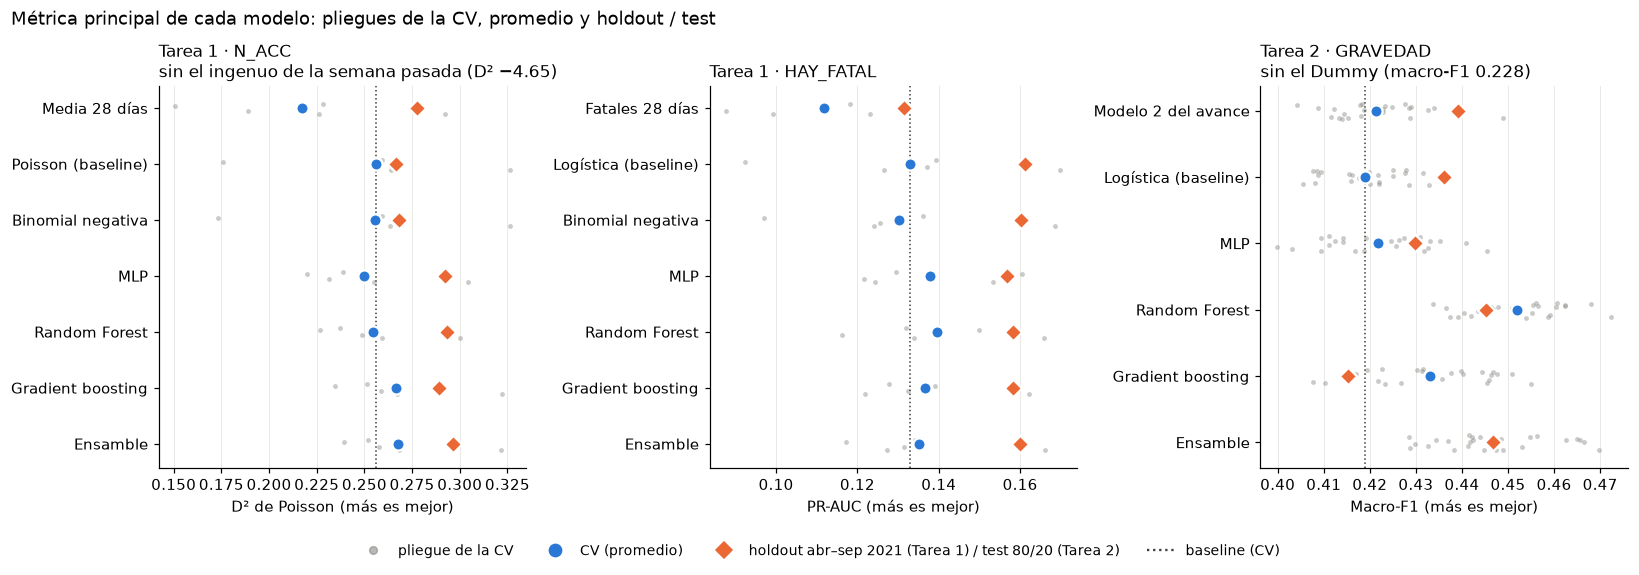

In [8]:
TITULOS = {"N_ACC": "Tarea 1 · N_ACC", "HAY_FATAL": "Tarea 1 · HAY_FATAL", "GRAVEDAD": "Tarea 2 · GRAVEDAD"}
FUERA = {"N_ACC": "sin el ingenuo de la semana pasada (D² −4.65)", "HAY_FATAL": "",
         "GRAVEDAD": f"sin el Dummy (macro-F1 {CV['GRAVEDAD'][REFERENCIA['GRAVEDAD']].macro_f1.mean():.3f})"}
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), sharey=False)
for ax, o in zip(axs, TAREA):
    m, etiqueta = PRINCIPAL[o]
    nombres = [n for n in CV[o] if not (o == "GRAVEDAD" and n == REFERENCIA[o])]
    ys = np.arange(len(nombres))[::-1]
    for y, n in zip(ys, nombres):
        ax.scatter(CV[o][n][m], np.full(len(CV[o][n]), y) + np.random.default_rng(0).uniform(-0.12, 0.12, len(CV[o][n])),
                   s=10, color=GRIS, alpha=0.45, lw=0, zorder=2)
    ax.scatter([CV[o][n][m].mean() for n in nombres], ys, s=64, color=AZUL, edgecolor="white", lw=1.5, zorder=3)
    ax.scatter([HOLD[o][n][m] for n in nombres], ys, s=64, marker="D", color=NARANJA, edgecolor="white", lw=1.5,
               zorder=4)
    ax.axvline(CV[o][BASELINE[o]][m].mean(), color=TINTA, ls=":", lw=1)
    ax.set_yticks(ys, [CORTO[n] for n in nombres])
    ax.set_xlabel(etiqueta + " (más es mejor)")
    ax.set_title(TITULOS[o] + ("\n" + FUERA[o] if FUERA[o] else ""), loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
manejadores = [plt.Line2D([], [], ls="", marker="o", ms=5, color=GRIS, alpha=0.6, label="pliegue de la CV"),
               plt.Line2D([], [], ls="", marker="o", ms=8, color=AZUL, label="CV (promedio)"),
               plt.Line2D([], [], ls="", marker="D", ms=7, color=NARANJA, label="holdout abr–sep 2021 (Tarea 1) / test 80/20 (Tarea 2)"),
               plt.Line2D([], [], ls=":", color=TINTA, label="baseline (CV)")]
fig.legend(handles=manejadores, ncols=4, loc="upper center", bbox_to_anchor=(0.5, 0.0), frameon=False, fontsize=9)
fig.suptitle("Métrica principal de cada modelo: pliegues de la CV, promedio y holdout / test", x=0.01, ha="left", y=1.03)
guardar(fig, "modelo_19_comparacion_metrica_principal.png")

### 4.2 Diferencia con el baseline (`modelo_20`)
Diferencia de la métrica principal con el baseline, pliegue a pliegue, con su IC 95 % aproximado. Relleno = el IC no
incluye el 0; vacío = empate. A la derecha, en cuántos pliegues gana el modelo. Las referencias sin ML frente al
baseline están en la tabla de §3.

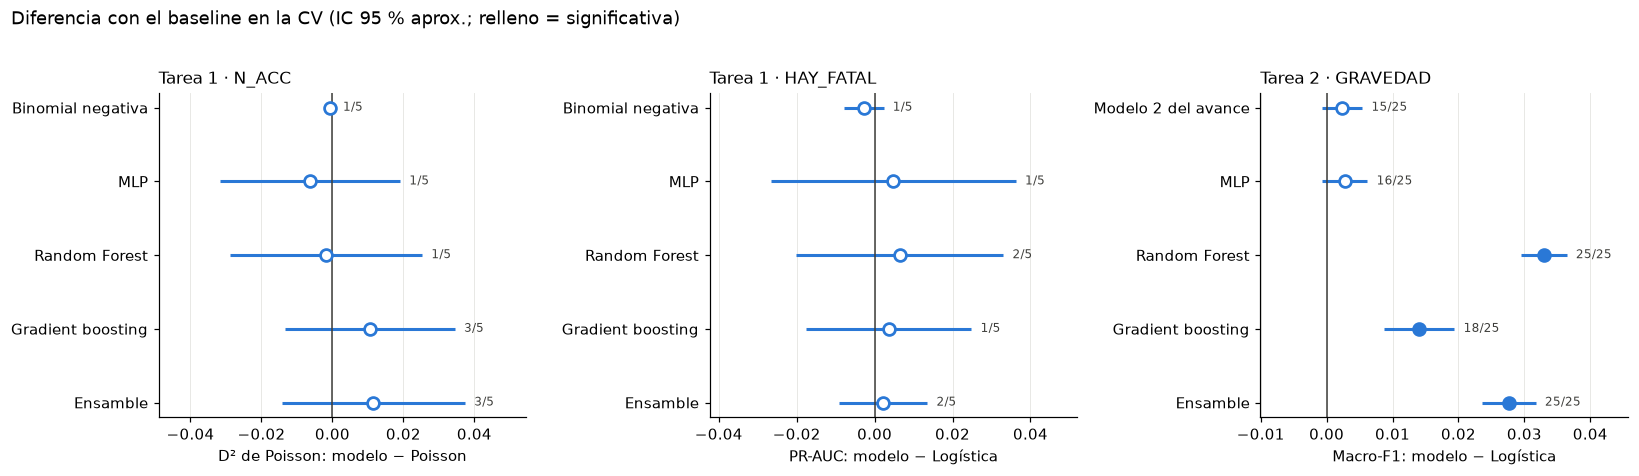

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, o in zip(axs, TAREA):
    d = pareada[(pareada.variable == o) & (pareada["frente a"] == CORTO[BASELINE[o]])
                & (pareada.modelo != REFERENCIA[o])].reset_index(drop=True)
    ys = np.arange(len(d))[::-1]
    ax.hlines(ys, d.ic_inf, d.ic_sup, color=AZUL, lw=2, zorder=2)
    for y, (_, f) in zip(ys, d.iterrows()):
        ax.scatter(f.dif, y, s=60, zorder=3, color=AZUL if f.significativa else "white", edgecolor=AZUL, lw=1.8)
        ax.annotate(f"{f.gana}/{f.pliegues}", (f.ic_sup, y), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=8, color=TINTA)
    ax.axvline(0, color=TINTA, lw=1)
    ax.set_yticks(ys, [CORTO[n] for n in d.modelo])
    ax.set_xlabel(f"{PRINCIPAL[o][1]}: modelo − {CORTO[BASELINE[o]].split(' (')[0]}")
    ax.set_title(TITULOS[o], loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.25)
fig.suptitle("Diferencia con el baseline en la CV (IC 95 % aprox.; relleno = significativa)", x=0.01, ha="left", y=1.02)
fig.tight_layout()
guardar(fig, "modelo_20_diferencias_baseline.png")

### 4.3 Triaje: equilibrio entre clases en el test (`modelo_21`)
En el triaje, dejar pasar un fatal cuesta más que confundir heridos con sin víctimas. A la izquierda, el recall de
cada clase en el test; a la derecha, el macro-F1 frente al recall de la clase fatal.

,sin víctimas,heridos,fatal,precision_fatal,macro_f1
Logística (baseline),0.553,0.388,0.511,0.213,0.436
MLP,0.520,0.403,0.489,0.224,0.430
Random Forest,0.515,0.555,0.274,0.248,0.445
Gradient boosting,0.481,0.528,0.253,0.187,0.415
Ensamble,0.539,0.483,0.374,0.232,0.447


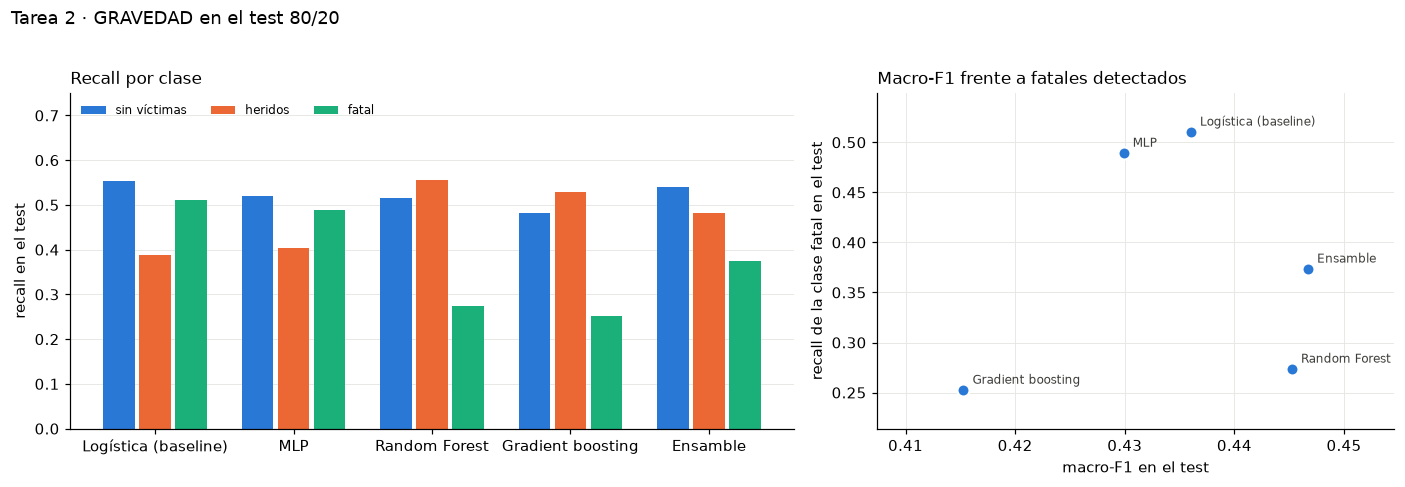

In [10]:
nombres = [n for n in PRED["GRAVEDAD"] if n not in (REFERENCIA["GRAVEDAD"], "Modelo 2 del avance (4 variables)")]
recall = pd.DataFrame({CORTO[n]: recall_score(te2.GRAVEDAD, PRED["GRAVEDAD"][n].argmax(1), average=None) for n in nombres},
                      index=M.CLASES_T2).T
prec_fatal = {CORTO[n]: precision_score(te2.GRAVEDAD == 2, PRED["GRAVEDAD"][n].argmax(1) == 2) for n in nombres}
display(recall.assign(precision_fatal=pd.Series(prec_fatal), macro_f1=[HOLD["GRAVEDAD"][n]["macro_f1"] for n in nombres]).round(3))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
ancho = 0.26
x = np.arange(len(recall))
for i, (clase, color) in enumerate(zip(M.CLASES_T2, (AZUL, NARANJA, AQUA))):
    axs[0].bar(x + (i - 1) * ancho, recall[clase], width=ancho - 0.03, color=color, label=clase, zorder=2)
axs[0].set_xticks(x, recall.index)
axs[0].set_ylabel("recall en el test")
axs[0].set_ylim(0, 0.75)
axs[0].grid(axis="x", visible=False)
axs[0].legend(fontsize=8, frameon=False, ncols=3, loc="upper left")
axs[0].set_title("Recall por clase", loc="left", fontsize=11)

for n in nombres:
    xv, yv = HOLD["GRAVEDAD"][n]["macro_f1"], recall.loc[CORTO[n], "fatal"]
    axs[1].scatter(xv, yv, s=64, color=AZUL, edgecolor="white", lw=1.5, zorder=3)
    axs[1].annotate(CORTO[n], (xv, yv), xytext=(6, 4), textcoords="offset points", fontsize=8, color=TINTA)
axs[1].set_xlabel("macro-F1 en el test")
axs[1].set_ylabel("recall de la clase fatal en el test")
axs[1].margins(x=0.25, y=0.15)
axs[1].set_title("Macro-F1 frente a fatales detectados", loc="left", fontsize=11)
fig.suptitle("Tarea 2 · GRAVEDAD en el test 80/20", x=0.01, ha="left", y=1.02)
fig.tight_layout()
guardar(fig, "modelo_21_t2_triaje_equilibrio.png")

### 4.4 Curvas precisión–recall de los fatales (`modelo_22`)
Baseline, mejor modelo individual en la CV y ensamble, con la referencia y el azar (prevalencia).

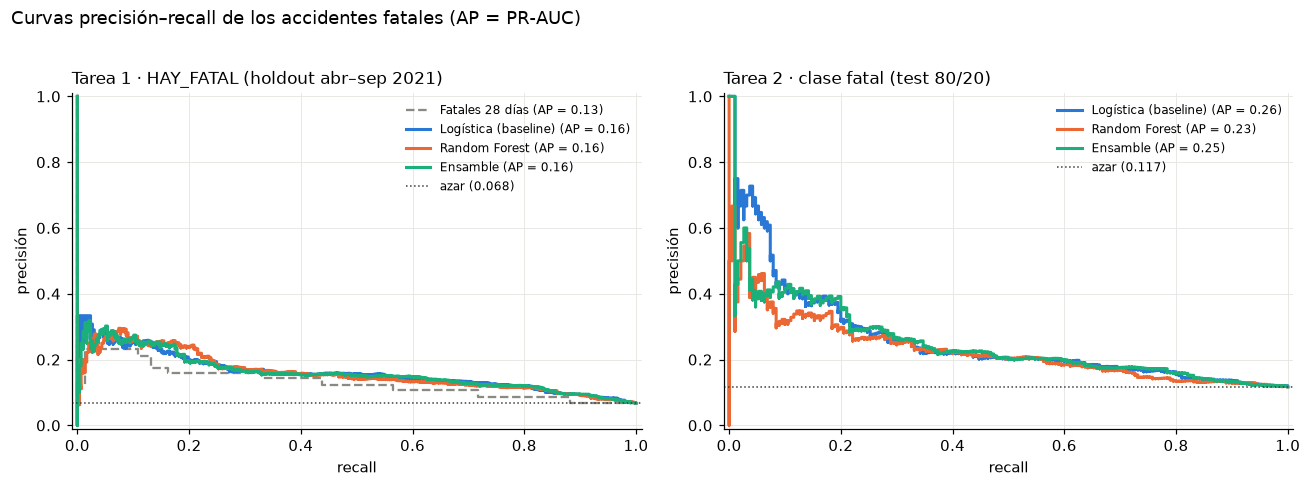

In [11]:
def mejor_individual(o, metrica):
    candidatos = [n for n in CV[o] if n not in (REFERENCIA[o], BASELINE[o], "Ensamble (votación)", "Modelo 2 del avance (4 variables)")]
    return max(candidatos, key=lambda n: CV[o][n][metrica].mean())


fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
casos = [("HAY_FATAL", te1.HAY_FATAL.to_numpy(), lambda p: p, "Tarea 1 · HAY_FATAL (holdout abr–sep 2021)"),
         ("GRAVEDAD", (te2.GRAVEDAD == 2).to_numpy(), lambda p: p[:, 2], "Tarea 2 · clase fatal (test 80/20)")]
for ax, (o, y, col, titulo) in zip(axs, casos):
    mejor = mejor_individual(o, PRINCIPAL[o][0])
    if o == "HAY_FATAL":
        PrecisionRecallDisplay.from_predictions(y, col(PRED[o][REFERENCIA[o]]), name=CORTO[REFERENCIA[o]], ax=ax,
                                                color=GRIS, ls="--", lw=1.5)
    for n, color in ((BASELINE[o], AZUL), (mejor, NARANJA), ("Ensamble (votación)", AQUA)):
        PrecisionRecallDisplay.from_predictions(y, col(PRED[o][n]), name=CORTO[n], ax=ax, color=color, lw=2)
    ax.axhline(y.mean(), color=TINTA, ls=":", lw=1, label=f"azar ({y.mean():.3f})")
    ax.set_aspect("auto"); ax.set_xlabel("recall"); ax.set_ylabel("precisión")
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.legend(fontsize=8, frameon=False)
fig.suptitle("Curvas precisión–recall de los accidentes fatales (AP = PR-AUC)", x=0.01, ha="left", y=1.02)
fig.tight_layout()
guardar(fig, "modelo_22_curvas_pr_fatal.png")

## 5. Veredicto por variable objetivo
Mejor modelo por la métrica principal en la CV y en el holdout / test, y si su diferencia con el baseline es
significativa (IC 95 % aprox. sin el 0).

In [12]:
filas = []
for o in TAREA:
    m = PRINCIPAL[o][0]
    medias = pd.Series({n: r[m].mean() for n, r in CV[o].items()})
    hold = pd.Series({n: HOLD[o][n][m] for n in CV[o]})
    mejor_cv, mejor_h = medias.idxmax(), hold.idxmax()
    d = pareada[(pareada.variable == o) & (pareada.modelo == mejor_cv) & (pareada["frente a"] == CORTO[BASELINE[o]])]
    filas.append({"variable": o, "métrica": PRINCIPAL[o][1],
                  "referencia (CV)": medias[REFERENCIA[o]], "baseline (CV)": medias[BASELINE[o]],
                  "mejor en CV": CORTO[mejor_cv], "su CV": medias[mejor_cv],
                  "frente al baseline": (f"{d.dif.iloc[0]:+.3f} [{d.ic_inf.iloc[0]:+.3f}, {d.ic_sup.iloc[0]:+.3f}]"
                                         if len(d) else "—"),
                  "mejor en holdout/test": CORTO[mejor_h], "su holdout/test": hold[mejor_h]})
veredicto = pd.DataFrame(filas).set_index("variable")
display(veredicto.round(3))

,métrica,referencia (CV),baseline (CV),mejor en CV,su CV,frente al baseline,mejor en holdout/test,su holdout/test
variable,,,,,,,,
N_ACC,D² de Poisson,0.217,0.256,Ensamble,0.268,"+0.012 [-0.014, +0.037]",Ensamble,0.296
HAY_FATAL,PR-AUC,0.112,0.133,Random Forest,0.140,"+0.006 [-0.020, +0.033]",Logística (baseline),0.161
GRAVEDAD,Macro-F1,0.228,0.419,Random Forest,0.452,"+0.033 [+0.029, +0.036]",Ensamble,0.447


## 6. Lectura
- **Tarea 1 · `N_ACC`.** Todos los modelos con aprendizaje superan a la media de 28 días en los 5 pliegues (+0.033 a
  +0.050 de D²), pero **ninguno supera al Poisson con un IC sin el 0**. Los mejores promedios en la CV son el ensamble
  (0.268) y el gradient boosting (0.267), unos 0.011 por encima del Poisson, y ganan en 3 de 5 pliegues. El holdout
  abr–sep 2021 separa a los modelos lineales de los no lineales: el Poisson y la binomial negativa (0.267–0.268) quedan
  por debajo de la media de 28 días (0.277), y el MLP, el RF, el GBM y el ensamble quedan por encima (0.289–0.296). Los
  cuatro modelos no lineales siguen mejor la subida de accidentes tras la cuarentena. **Elección: el ensamble por
  votación** (mejor en la CV y en el holdout), aunque su ventaja sobre el GBM es mínima.
- **Tarea 1 · `HAY_FATAL`.** Empate entre todos los modelos: PR-AUC de 0.130 a 0.140 en la CV y de 0.157 a 0.161 en el
  holdout, unas 2.4 veces el azar (0.068). Ningún modelo supera a la logística con un IC sin el 0. Frente a la
  referencia de los fatales de los últimos 28 días, el MLP, el RF, el GBM y el ensamble sí ganan con un IC sin el 0 (+0.023
  a +0.028); la logística gana en 4 de 5 pliegues, pero su IC incluye el 0. Las curvas de `modelo_22` casi se
  superponen. **Elección: la logística**: es la más simple, está bien calibrada (Brier 0.060) y tiene la mejor PR-AUC en
  el holdout (0.161). Con estas variables, la señal para anticipar un día con un fatal es débil para cualquier modelo.
- **Tarea 2 · `GRAVEDAD`.** Es la única tarea en que los árboles mejoran claramente al modelo lineal. En macro-F1, el
  RF (+0.033, 25 de 25 pliegues), el ensamble (+0.028, 25 de 25) y el GBM (+0.014, 18 de 25) superan a la logística
  con un IC sin el 0; el MLP y el Modelo 2 del avance empatan. La mejora viene de separar sin víctimas de heridos. En
  la clase fatal ningún modelo supera a la logística (PR-AUC 0.266): el ensamble y el RF empatan, y el MLP y el GBM
  quedan por debajo. En el test, `modelo_21` muestra el dilema: la logística y el MLP detectan la mitad de los
  fatales (recall 0.51 y 0.49), pero con menos macro-F1 que el RF y el ensamble; el RF y el GBM detectan uno de cada cuatro (0.27 y 0.25); y el
  ensamble queda en medio (0.37) con el mejor macro-F1 del test (0.447). **Elección: depende del uso.** Si se mide con
  la métrica principal, gana el RF (0.452 en la CV). Para un despacho que no puede dejar pasar fatales, conviene la
  logística. El ensamble es el punto medio: no queda por debajo del baseline en ninguna métrica.
- **En conjunto.** Pasar de un modelo lineal a uno no lineal ayuda donde hay interacciones que aprender: el tipo de
  accidente con la vía y la hora en el triaje, y el cambio de nivel tras la cuarentena en el conteo. No ayuda en
  `HAY_FATAL`, donde la señal es débil. Las mejoras son modestas (+0.01 a +0.03) frente a lo que reporta la bibliografía,
  que trabaja con más registros y con variables del vehículo y de las personas que este registro no tiene.
- **Reproducibilidad.** 20 de 21 modelos reproducen `metrics.csv` con una diferencia menor que 0.002. La excepción es el
  gradient boosting de `GRAVEDAD`, cuyo macro-F1 del test cambia entre máquinas (0.415 aquí, 0.427 en
  `04_gradient_boosting.ipynb`) aunque sus probabilidades casi no cambian (ver `06_mlp.ipynb` §4.4). La Tabla I usa
  los valores de `metrics.csv`; las figuras, los de esta reevaluación.